# **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

import statsmodels.api as sm
from scipy.stats import f
import matplotlib.pyplot as plt 
import seaborn as sns
plt.style.use('ggplot')
from scipy.stats import spearmanr, kendalltau
from scipy.stats import norm, chi2
from statsmodels.tsa.stattools import zivot_andrews
from statsmodels.tsa.stattools import adfuller

# **Data Preparation**

### **Load the data**

In [2]:
data = pd.read_csv('wdi_data.csv')
data['Value'] = pd.to_numeric(data['Value'], errors = 'coerce')
data['Time'] = pd.to_datetime(data['Time'])
data.sort_values(by = ['Country Name', 'Time', 'Series Name'])
data.head(2)

,Country Name,Country Code,Series Name,Series Code,Time,Time Code,Value
0,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1970-01-01 00:00:00.000002025,YR2025,11.424022
1,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1970-01-01 00:00:00.000002024,YR2024,11.164801


In [3]:
print(f'Number of unique countries: {data['Country Code'].nunique()}')
print(f'Number of lags: {data['Time'].nunique()}')
print(f'Number of Indicators: {data['Series Code'].nunique()}')

Number of unique countries: 9
Number of lags: 50
Number of Indicators: 24


In [4]:
series = pd.DataFrame({'Series' : data['Series Name'].unique()})
series

,Series
0,"Agriculture, forestry, and fishing, value adde..."
1,Exports of goods and services (% of GDP)
2,"Foreign direct investment, net inflows (% of GDP)"
3,GDP (constant 2015 US$)
4,GDP growth (annual %)
5,GDP per capita (constant 2015 US$)
6,GDP per capita growth (annual %)
7,Gross fixed capital formation (% of GDP)
8,Gross fixed capital formation (annual % growth)
9,Gross fixed capital formation (constant 2015 US$)


In [5]:
print('Top countries with the highest maximum foreign investments % of GDP')

(
    data[data['Series Name'] == 'Foreign direct investment, net inflows (% of GDP)']
    .groupby('Country Name')['Value']
    .agg(max_ever_percentage='max', median_percentage = 'median', min_percentage = 'min')
    .sort_values(by='max_ever_percentage', ascending=False)
    .head(5)
)

Top countries with the highest maximum foreign investments % of GDP


,max_ever_percentage,median_percentage,min_percentage
Country Name,,,
Singapore,32.262485,15.268453,3.646085
Viet Nam,11.939483,4.278323,-0.000568
Malaysia,8.760474,3.501092,0.056692
China,6.161583,2.149573,0.000045
Philippines,3.122388,1.307479,-0.287668


In [6]:
print('Top countries with the sorted GPD per capita growth')
data[data['Series Name'] == 'GDP per capita growth (annual %)'].groupby('Country Name')['Value']\
.agg(median_growth_percentage = 'median',
     mean_growth_percentage='mean',
     max_growth_percentage='max').sort_values(by = 'median_growth_percentage', ascending = False)

Top countries with the sorted GPD per capita growth


,median_growth_percentage,mean_growth_percentage,max_growth_percentage
Country Name,,,
China,7.630738,7.722661,13.690607
"Korea, Rep.",5.271189,5.282195,11.806326
Viet Nam,5.237177,4.960347,7.725699
Indonesia,4.174277,3.541409,7.286559
Singapore,4.128894,4.074477,14.831461
Malaysia,3.761559,3.378917,8.922229
Bangladesh,3.283302,3.416922,6.972644
Philippines,2.764092,1.970102,6.765954
Japan,1.825062,1.730927,6.341600


In [7]:
data = data.pivot(index = ['Country Name', 'Time'], columns = 'Series Name', values = 'Value').reset_index().copy()
data['Time'] = pd.to_numeric(data['Time'])
data.head()

Series Name,Country Name,Time,"Agriculture, forestry, and fishing, value added (% of GDP)",Exports of goods and services (% of GDP),"Foreign direct investment, net inflows (% of GDP)",GDP (constant 2015 US$),GDP growth (annual %),GDP per capita (constant 2015 US$),GDP per capita growth (annual %),Gross fixed capital formation (% of GDP),...,"Manufacturing, value added (annual % growth)","Manufacturing, value added (constant 2015 US$)",Population growth (annual %),"Population, female","Population, female (% of total population)","Population, male","Population, male (% of total population)","Population, total","Services, value added (% of GDP)",Trade (% of GDP)
0,Bangladesh,1976,51.914457,4.746082,0.053573,3.070513e+10,5.661361,384.509552,3.013762,NaN,...,-0.690863,2.446962e+09,2.537669,38756724.0,48.533679,41098594.0,51.466321,79855318.0,33.636340,22.382275
1,Bangladesh,1977,48.898057,7.040752,0.072323,3.152590e+10,2.673056,385.085520,0.149793,NaN,...,11.659954,2.732277e+09,2.488273,39758252.0,48.564286,42109012.0,51.435714,81867264.0,34.372869,19.422198
2,Bangladesh,1978,54.250308,5.557663,0.057974,3.375599e+10,7.073838,402.385596,4.492528,NaN,...,1.177488,2.764449e+09,2.440310,40766279.0,48.595121,43123376.0,51.404879,83889655.0,31.439979,21.038515
3,Bangladesh,1979,52.452012,6.109219,-0.051460,3.537683e+10,4.801635,411.669267,2.307158,NaN,...,11.190006,3.073791e+09,2.408973,41786802.0,48.626016,44148270.0,51.373984,85935072.0,31.861533,21.907064
4,Bangladesh,1980,32.823892,5.494284,0.046918,3.566661e+10,0.819142,405.226770,-1.564969,14.439391,...,2.325027,3.145257e+09,2.393149,42826188.0,48.657037,45190244.0,51.342963,88016432.0,44.555666,23.377231


### Variable Creation

$$NTC_{it} = \frac{\text{Exports (\% of GDP)}_{it} - \text{Imports (\% of GDP)}_{it}}{\text{Trade (\% of GDP)}_{it}}$$

Ozawa, T. (2003). "Pax Americana-led macro-clustering and flying-geese-style catch-up in East Asia: mechanisms of regionalized endogenous growth." Journal of Asian Economics, 13(6), 699–713. DOI: 10.1016/S1049-0078(02)00180-X

In [8]:
# Trade Balance

data['Trade Balance of goods and services (% of GDP)'] = data['Exports of goods and services (% of GDP)'] - data['Imports of goods and services (% of GDP)']
data['Net Trade competitiveness ratio'] = (data['Exports of goods and services (% of GDP)'] - data['Imports of goods and services (% of GDP)']) / data['Trade (% of GDP)']

### Smoothing

In [9]:
data['Manufacturing, value added smooth (% of GDP)'] = data.groupby('Country Name')['Manufacturing, value added (% of GDP)'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

# **Statistical Tests**

**Chow's Test**

If there is a split in between the sample size for any given cut off points by the $N = N_1 + N_2$

The Hypothesis:

$Null \ Hypotehsis \ H_0:$ 

$\beta_{1, 0} = \beta_{2, 0},\ \beta_{1, 1} = \beta_{2, 1},\ \dots,\ \beta_{1, k} = \beta_{2, k}$

*(A single pooled regression line represents the entire dataset just as effectively as two separate regressions.)*

Alternative Hypothesis ($H_1$): At least one parameter differs between the two groups ($\beta_{1,j} \neq \beta_{2,j}$ for some $j$), indicating a structural break.

Paper Link: http://people.stat.ucla.edu/nchristo/statistics100C/testing_equations_paper.pdf

BibTeX:

@article{chow1960tests,

  title={Tests of equality between sets of coefficients in two linear regressions},

  author={Chow, Gregory C},

  journal={Econometrica: Journal of the Econometric Society},

  volume={28},

  number={3},

  pages={591--605},

  year={1960},

  publisher={JSTOR},

  doi={10.2307/1910133}
  
}

In [10]:
def chow_test(data, time_col, break_year, y_col, x_cols):
    df_1 = data[data[time_col] < break_year]
    df_2 = data[data[time_col] >= break_year]
    
    y_p = data[y_col]
    X_p = sm.add_constant(data[x_cols])
    model_p = sm.OLS(y_p, X_p).fit()
    rss_p = model_p.ssr
    coeffs = model_p.params[x_cols]
    
    y_1 = df_1[y_col]
    X_1 = sm.add_constant(df_1[x_cols])
    rss_1 = sm.OLS(y_1, X_1).fit().ssr
    
    y_2 = df_2[y_col]
    X_2 = sm.add_constant(df_2[x_cols])
    rss_2 = sm.OLS(y_2, X_2).fit().ssr
    
    k = X_p.shape[1]
    n_1 = len(df_1)
    n_2 = len(df_2)
    
    numerator = (rss_p - (rss_1 + rss_2)) / k
    denominator = (rss_1 + rss_2) / (n_1 + n_2 - 2 * k)
    
    f_stat = numerator / denominator
    p_val = 1 - f.cdf(f_stat, k, n_1 + n_2 - 2 * k)
    
    return f_stat, p_val, coeffs


In [11]:

y_variable = 'GDP growth (annual %)'
x_variables = ['Gross fixed capital formation (% of GDP)', 'Trade Balance of goods and services (% of GDP)', 'Manufacturing, value added (% of GDP)', 'Trade (% of GDP)'\
               , 'Foreign direct investment, net inflows (% of GDP)']
palette = {
    'Bangladesh': '#E63946',
    'Indonesia': '#2A9D8F',
    'Viet Nam': '#F4A261',
    'Malaysia': '#457B9D',
    'China': '#8338EC',
    'Japan': '#1D3557'
}
def condition(country:str, cutoff:int, x = x_variables, y = y_variable, display:bool=True, alpha:float=0.05, coefficients:bool = False):
    country_df = data[data['Country Name'] == country].sort_values('Time').dropna(
    subset=x + [y]
    )
    f_statistic, p_value, coeff = chow_test(country_df, 'Time', cutoff, y, x)
    
    decision = f'Decision: {'There was an effect' if p_value<alpha else 'There was no effect'}'
    if display == True:
        print(f"Chow's Test Statistics Results for {cutoff} F-statistic: {f_statistic:.4f}, p-value: {p_value:.4e}")
        plt.figure(figsize = (20, 10))
        sns.lineplot(data = country_df,  x = 'Time', y = y, palette = palette, linewidth = 2)
        plt.text(cutoff, country_df[y].quantile(0.75), decision+' on '+f'{cutoff}', fontsize=14, fontweight='bold', color='red' if decision == 'Decision: There was an effect' else 'green', bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))
        plt.axvline(x=cutoff, color='red', linestyle='--')
        plt.title(f'GDP growth (annual %) for {country}')
        plt.show()
    if coefficients == True:
        print('Here are the coefficient results for Chow Test:')
        print(coeff)

    return decision


### Observing Country-wise GDP Growth Annually

In [12]:

effects = {
    'Country Name': [],
    'Years': []
}
for c in data['Country Name'].unique():
    country_check = data[data['Country Name'] == c].dropna(subset=x_variables + [y_variable])
    if len(country_check) <= 2 * (len(x_variables) + 1):
        continue
    effective_times = []
    for i in range(1995, 2021):
        if len(country_check[country_check['Time'] < i]) <= len(x_variables) + 1 or len(country_check[country_check['Time'] >= i]) <= len(x_variables) + 1:
            continue
        decision = condition(c, i, display = False, alpha = 0.05)
        if decision == 'Decision: There was an effect':
            effective_times.append(i)
    effects['Years'].append(effective_times)
    effects['Country Name'].append(c)

pd.DataFrame(effects)

,Country Name,Years
0,Bangladesh,[2019]
1,China,[]
2,Indonesia,"[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200..."
3,Japan,[]
4,"Korea, Rep.","[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200..."
5,Malaysia,"[1999, 2000, 2005, 2013, 2014, 2015, 2016, 201..."
6,Philippines,"[2016, 2017, 2018, 2019]"
7,Singapore,[]
8,Viet Nam,[2019]


In [13]:
for i in range(2005, 2022):
    decision = condition('Bangladesh', i, display = False, alpha = 0.05, coefficients = False)
    print(i, ':' , decision if decision == 'Decision: There was an effect' else 'None')

2005 : None
2006 : None
2007 : None
2008 : None
2009 : None
2010 : None
2011 : None
2012 : None
2013 : None
2014 : None
2015 : None
2016 : None
2017 : None
2018 : None
2019 : Decision: There was an effect
2020 : Decision: There was an effect
2021 : None


C:\Users\moham\AppData\Local\Temp\ipykernel_2880\1336042528.py:17: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  rss_2 = sm.OLS(y_2, X_2).fit().ssr


### The "Kojima FDI-Upgrading" Quadrant (FDI vs. High-Tech Transition)

*This chart will starkly illustrate Bangladesh’s core anomaly: while Vietnam, Malaysia, and China sit in the high-FDI / high-tech-export quadrant, Bangladesh remains anchored in the bottom-left corner (FDI < 1.5% of GDP and High-Tech Exports < 1% of manufactured exports), relying heavily on domestic Gross fixed capital formation (% of GDP) rather than foreign technology transfer.*

Reference Link: Kojima, K. (2000). "The 'flying geese' model of Asian economic development: origin, theoretical extensions, and regional policy implications." Journal of Asian Economics, 11(4), 375–401. DOI: 10.1016/S1049-0078(00)00067-1




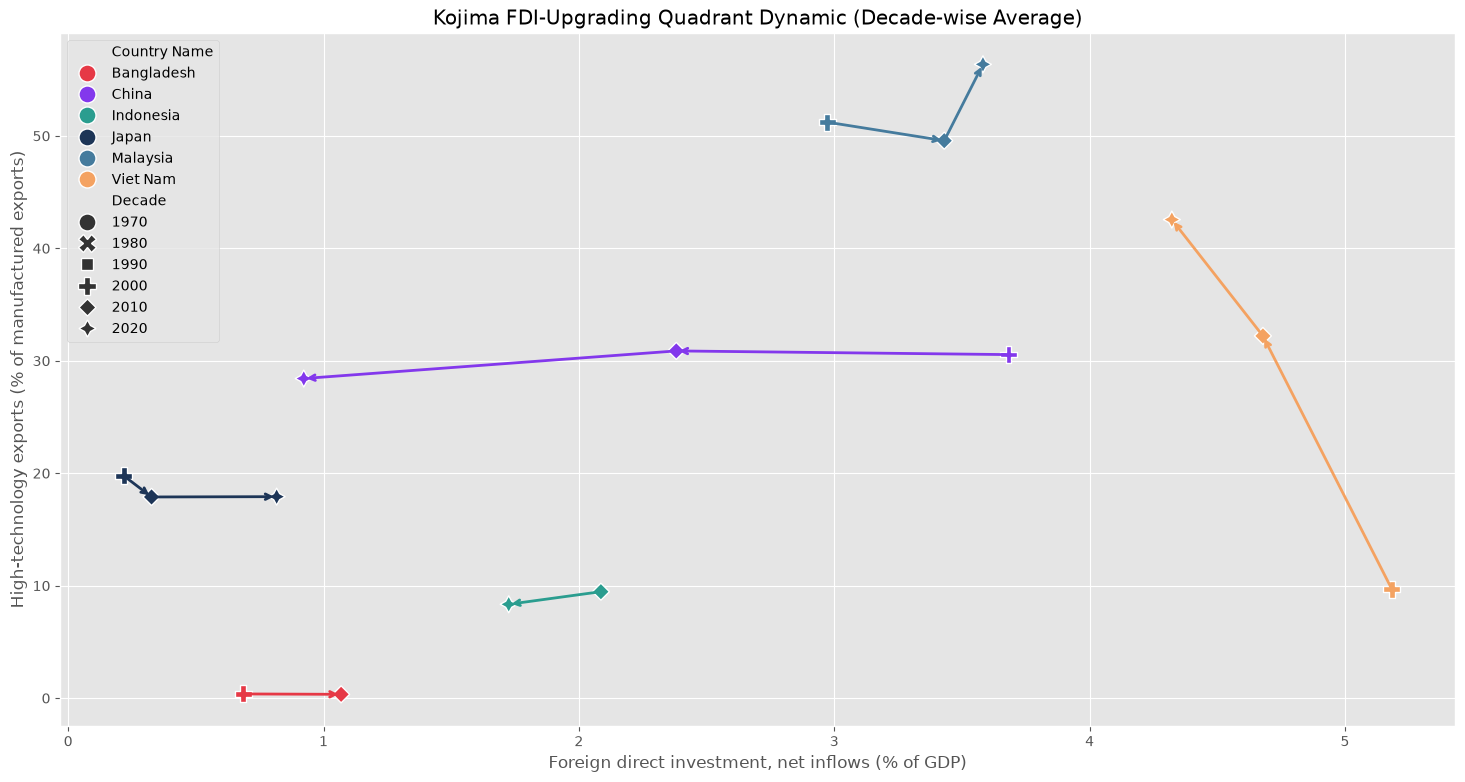

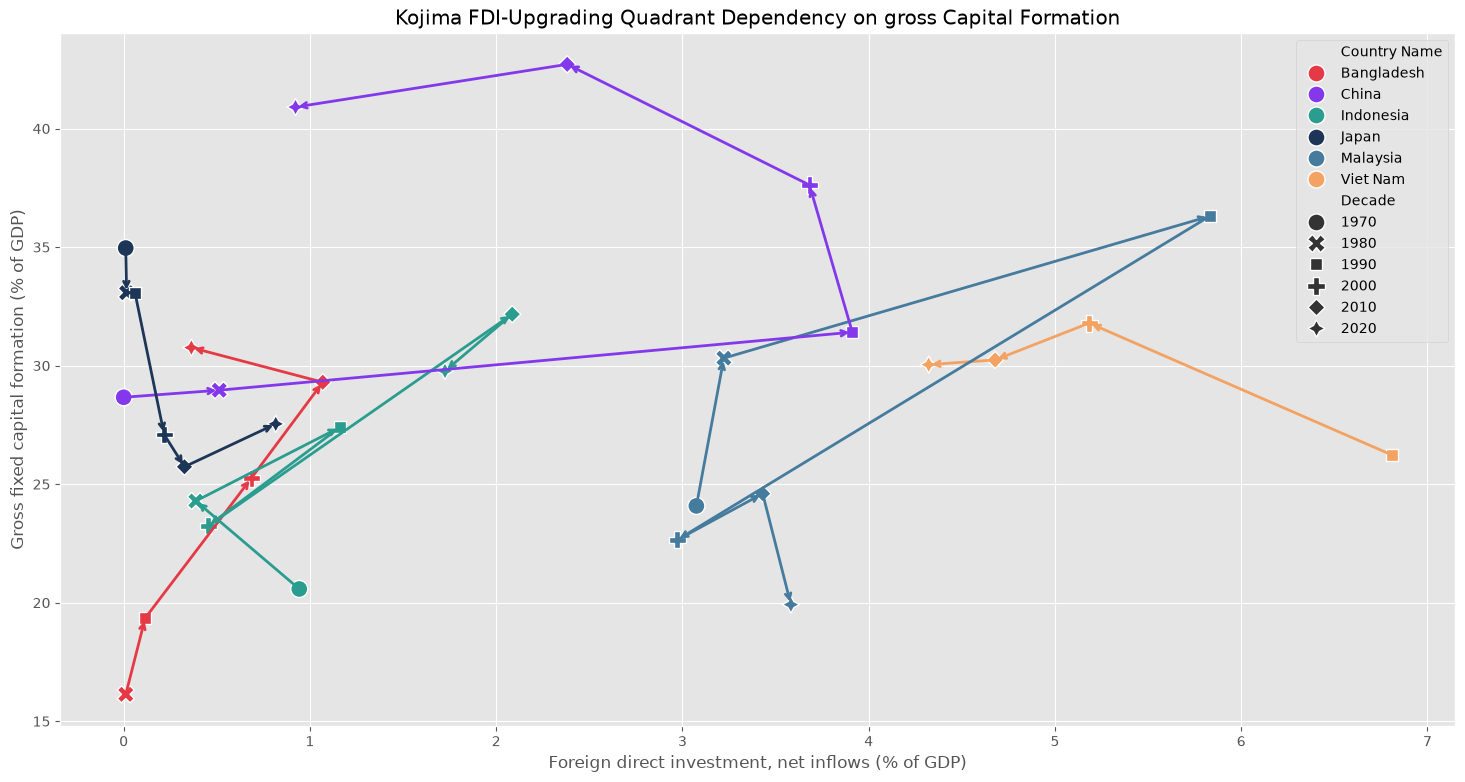

In [14]:
countries = ['Bangladesh', 'Indonesia', 'Viet Nam', 'Malaysia', 'China', 'Japan']
cols = ['Foreign direct investment, net inflows (% of GDP)', 'High-technology exports (% of manufactured exports)', 'Gross fixed capital formation (% of GDP)']

decade_df = data[data['Country Name'].isin(countries)].copy()
decade_df['Decade'] = (decade_df['Time'] // 10) * 10
decade_df = decade_df.groupby(['Country Name', 'Decade'], as_index=False)[cols].mean().sort_values(['Country Name', 'Decade'])



plt.figure(figsize = (18, 9))
sns.scatterplot(data = decade_df, x = 'Foreign direct investment, net inflows (% of GDP)', y = 'High-technology exports (% of manufactured exports)', hue = 'Country Name', style = 'Decade', palette = palette, s = 150)
for c in countries:
    sub = decade_df[decade_df['Country Name'] == c].dropna(subset=['Foreign direct investment, net inflows (% of GDP)', 'High-technology exports (% of manufactured exports)']).reset_index(drop=True)
    for i in range(len(sub) - 1):
        plt.annotate('', xy=(sub.loc[i+1, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i+1, 'High-technology exports (% of manufactured exports)']), xytext=(sub.loc[i, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i, 'High-technology exports (% of manufactured exports)']), arrowprops=dict(arrowstyle='->', color=palette[c], lw=2))
plt.title('Kojima FDI-Upgrading Quadrant Dynamic (Decade-wise Average)')
plt.show()

plt.figure(figsize = (18, 9))
sns.scatterplot(data = decade_df, x = 'Foreign direct investment, net inflows (% of GDP)', y = 'Gross fixed capital formation (% of GDP)', hue = 'Country Name', style = 'Decade', palette = palette, s = 150)
for c in countries:
    sub = decade_df[decade_df['Country Name'] == c].dropna(subset=['Foreign direct investment, net inflows (% of GDP)', 'Gross fixed capital formation (% of GDP)']).reset_index(drop=True)
    for i in range(len(sub) - 1):
        plt.annotate('', xy=(sub.loc[i+1, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i+1, 'Gross fixed capital formation (% of GDP)']), xytext=(sub.loc[i, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i, 'Gross fixed capital formation (% of GDP)']), arrowprops=dict(arrowstyle='->', color=palette[c], lw=2))
plt.title('Kojima FDI-Upgrading Quadrant Dependency on gross Capital Formation')
plt.show()

### Gendered Labor Absorption & Demographic Dividend Profile
Early-stage Flying Geese industrialization relies heavily on elastic labor supply and female labor absorption into light manufacturing (apparel/textiles).

Ozawa, T. (2005). Institutions, Industrial Upgrading, and Economic Performance in Japan: The 'Flying-Geese' Paradigm of Catch-up Growth. Edward Elgar Publishing (Specifically Chapter 2: Labor-Driven Stage – and Logic – of Reconstruction). Link to Book Source

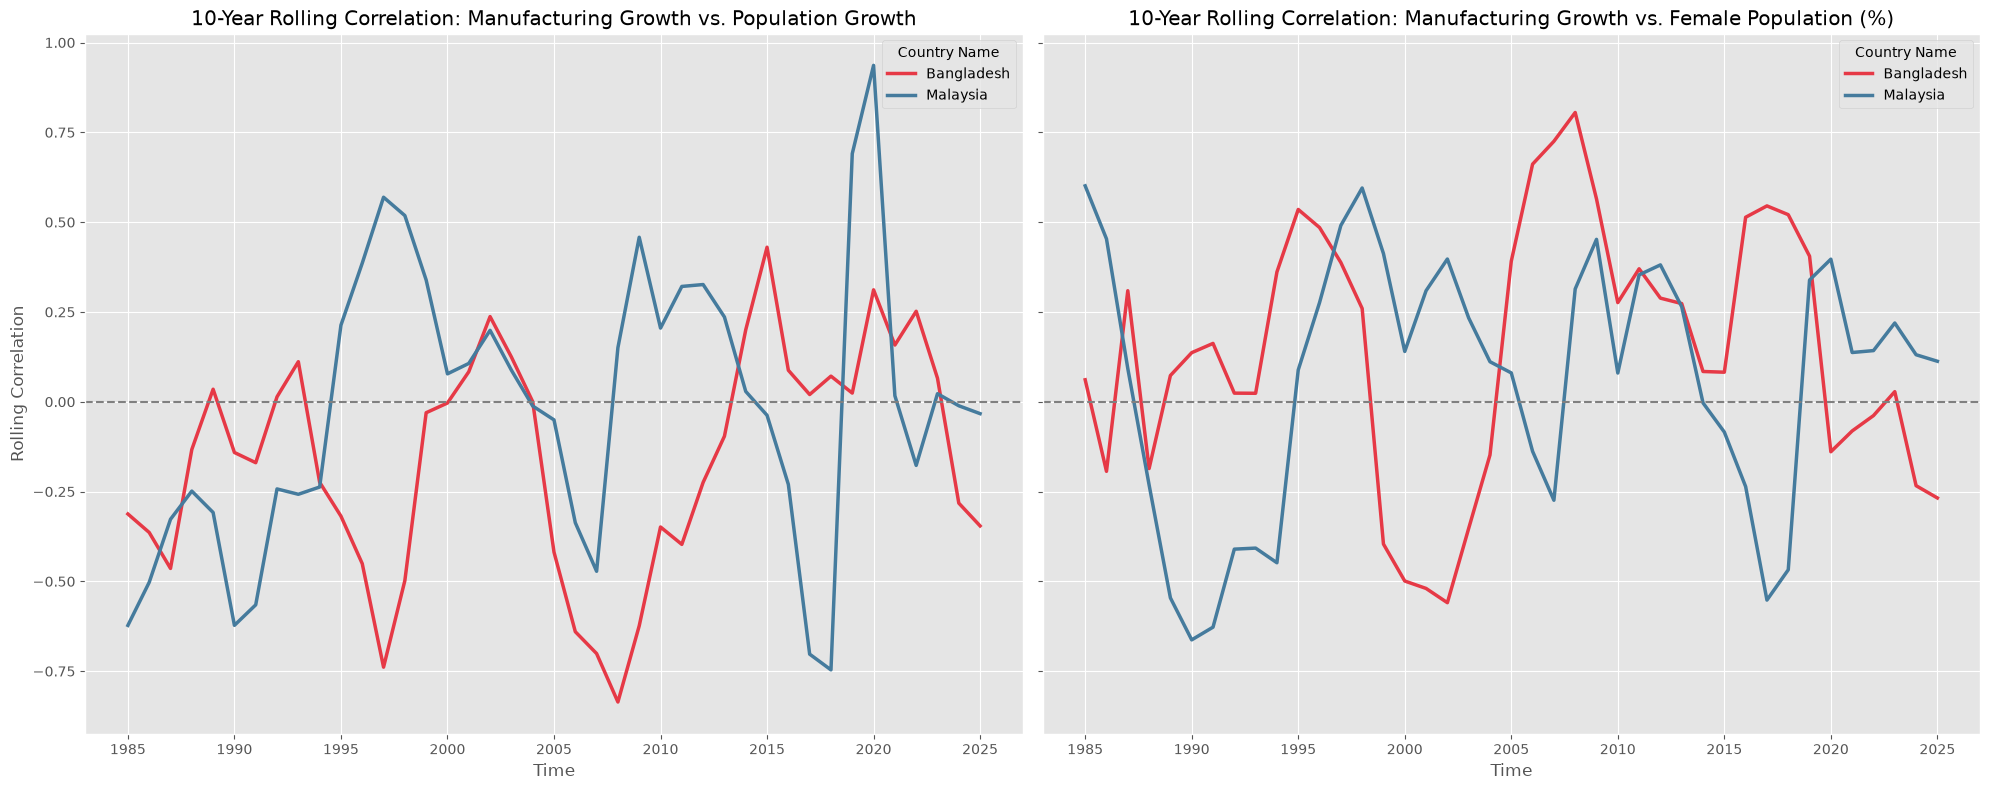

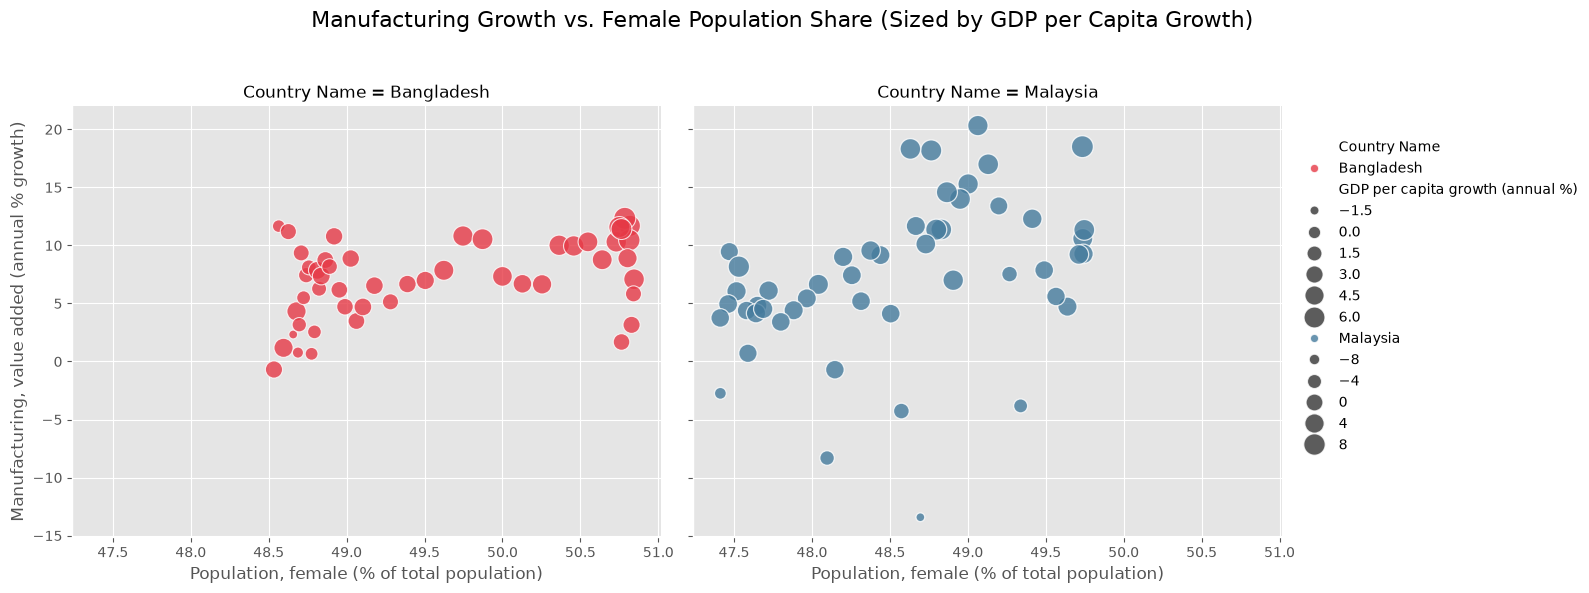

In [15]:
target_countries = ['Bangladesh', 'Malaysia']
vars_list = [
    'Population, female (% of total population)',
    'Population growth (annual %)',
    'Manufacturing, value added (annual % growth)',
    'GDP per capita growth (annual %)'
]

sub_df = data[data['Country Name'].isin(target_countries)].sort_values(['Country Name', 'Time']).dropna(subset=vars_list).copy()

sub_df['Roll_Corr_PopGrowth'] = sub_df.groupby('Country Name').apply(
    lambda g: g['Manufacturing, value added (annual % growth)'].rolling(10).corr(g['Population growth (annual %)'])
).reset_index(level=0, drop=True)

sub_df['Roll_Corr_FemalePop'] = sub_df.groupby('Country Name').apply(
    lambda g: g['Manufacturing, value added (annual % growth)'].rolling(10).corr(g['Population, female (% of total population)'])
).reset_index(level=0, drop=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

sns.lineplot(data=sub_df, x='Time', y='Roll_Corr_PopGrowth', hue='Country Name', palette=palette, linewidth=2.5, ax=axes[0])
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title('10-Year Rolling Correlation: Manufacturing Growth vs. Population Growth')
axes[0].set_ylabel('Rolling Correlation')

sns.lineplot(data=sub_df, x='Time', y='Roll_Corr_FemalePop', hue='Country Name', palette=palette, linewidth=2.5, ax=axes[1])
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('10-Year Rolling Correlation: Manufacturing Growth vs. Female Population (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

g = sns.FacetGrid(sub_df, col='Country Name', height=6, aspect=1.1)
g.map_dataframe(sns.scatterplot, x='Population, female (% of total population)', y='Manufacturing, value added (annual % growth)', hue='Country Name', palette=palette, size='GDP per capita growth (annual %)', sizes=(40, 250), alpha=0.8)
g.add_legend()
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Manufacturing Growth vs. Female Population Share (Sized by GDP per Capita Growth)', fontsize=16)
plt.show()

### Spearman Correlation and Kendall's $\tau$

Dowling, M., & Cheang, C. T. (2000). "Shifting comparative advantage in Asia: new tests of the 'flying geese' model." Journal of Asian Economics, 11(4), 443–463. DOI: 10.1016/S1049-0078(00)00070-1

In [16]:
lead_countries = ['China', 'Korea, Rep.', 'Viet Nam']
variables = ['Manufacturing, value added (% of GDP)', 'High-technology exports (% of manufactured exports)']
lags = [0, 5, 10]

results = []

for var in variables:
    pivoted = data.pivot(index='Time', columns='Country Name', values=var).sort_index()
    bd_series = pivoted['Bangladesh']
    
    for lead in lead_countries:
        if lead not in pivoted.columns:
            continue
        for k in lags:
            lead_lagged = pivoted[lead].shift(k)
            valid = pd.concat([bd_series, lead_lagged], axis=1).dropna()
            
            if len(valid) > 2:
                rho, sp_pval = spearmanr(valid.iloc[:, 0], valid.iloc[:, 1])
                tau, kt_pval = kendalltau(valid.iloc[:, 0], valid.iloc[:, 1])
                
                results.append({
                    'Variable': var,
                    'Lead Goose': lead,
                    'Lag (k)': k,
                    'Spearman Rho': rho,
                    'Spearman p-val': sp_pval,
                    'Kendall Tau': tau,
                    'Kendall p-val': kt_pval
                })

results_df = pd.DataFrame(results)
results_df

,Variable,Lead Goose,Lag (k),Spearman Rho,Spearman p-val,Kendall Tau,Kendall p-val
0,"Manufacturing, value added (% of GDP)",China,0,-0.937888,1.191823e-10,-0.818182,5.687024e-10
1,"Manufacturing, value added (% of GDP)",China,5,-0.958333,1.446991e-09,-0.852941,2.394031e-08
2,"Manufacturing, value added (% of GDP)",China,10,-0.804196,1.614769e-03,-0.636364,3.181647e-03
3,"Manufacturing, value added (% of GDP)","Korea, Rep.",0,0.571285,1.472156e-05,0.389388,6.606295e-05
4,"Manufacturing, value added (% of GDP)","Korea, Rep.",5,0.674045,3.863198e-07,0.470707,5.150530e-06
5,"Manufacturing, value added (% of GDP)","Korea, Rep.",10,0.686116,1.025129e-06,0.510256,3.533114e-06
6,"Manufacturing, value added (% of GDP)",Viet Nam,0,0.871429,2.708908e-07,0.685714,2.402167e-06
7,"Manufacturing, value added (% of GDP)",Viet Nam,5,0.829412,7.088454e-05,0.633333,3.362968e-04
8,"Manufacturing, value added (% of GDP)",Viet Nam,10,0.609091,4.669571e-02,0.527273,2.638448e-02
9,High-technology exports (% of manufactured exp...,China,0,-0.151515,6.760652e-01,-0.111111,7.274895e-01


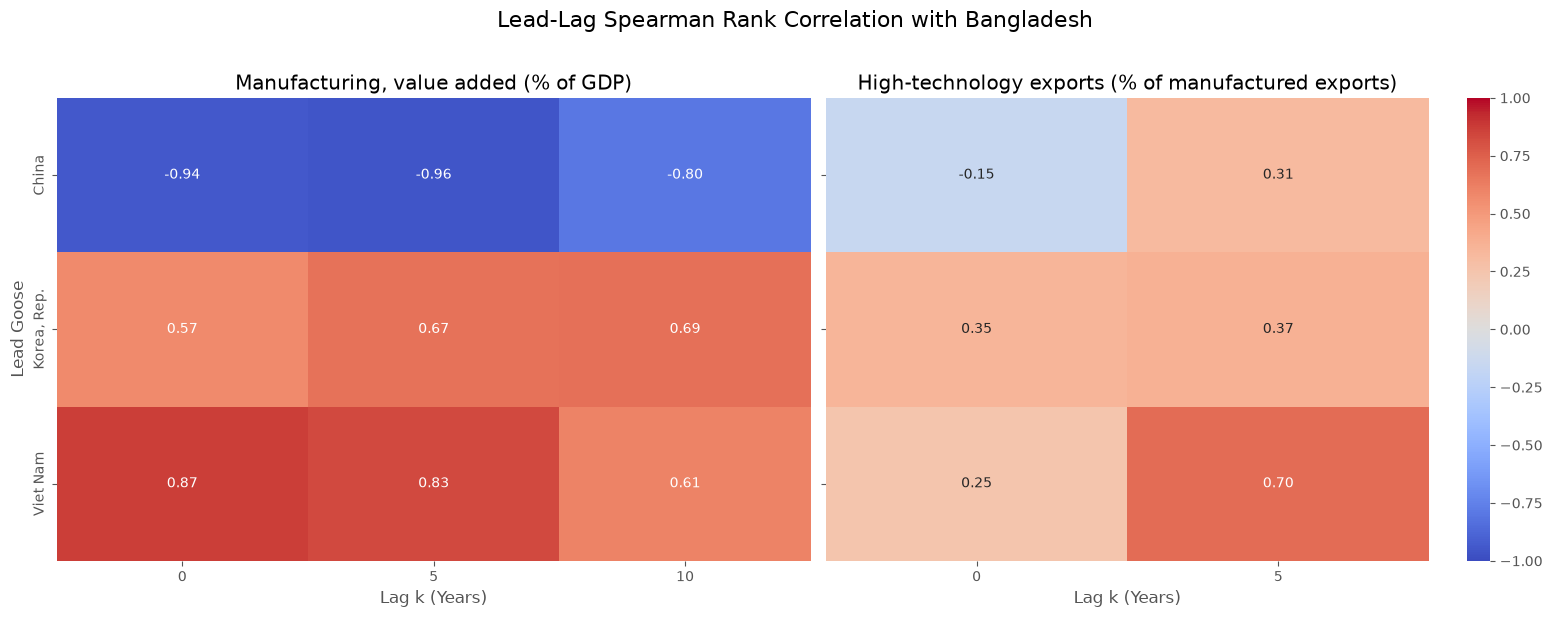

In [17]:
fig, axes = plt.subplots(1, len(variables), figsize=(16, 6), sharey=True)

for i, var in enumerate(variables):
    sub_res = results_df[results_df['Variable'] == var].pivot(index='Lead Goose', columns='Lag (k)', values='Spearman Rho')
    sns.heatmap(sub_res, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=axes[i], cbar=(i == len(variables) - 1))
    axes[i].set_title(var)
    axes[i].set_xlabel('Lag k (Years)')
    if i > 0:
        axes[i].set_ylabel('')

plt.suptitle('Lead-Lag Spearman Rank Correlation with Bangladesh', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Pesaran (2004) Cross-Sectional Dependence (CD) Test	Panel Diagnostic: Since your 9 Asian

Pesaran, M. H. (2004). "General diagnostic tests for cross section dependence in panels." Cambridge Working Papers in Economics, No. 0435 / Empirical Economics (2021). DOI: 10.17863/CAM.5113 / SSRN: 572504

In [18]:
def pesaran_cd_test(df, var):
    pivoted = df.pivot(index='Time', columns='Country Name', values=var).dropna(axis=1, how='all')
    N = pivoted.shape[1]
    corr_matrix = pivoted.corr()
    
    cd_sum = 0
    for i in range(N - 1):
        for j in range(i + 1, N):
            s_i = pivoted.iloc[:, i]
            s_j = pivoted.iloc[:, j]
            valid = pd.concat([s_i, s_j], axis=1).dropna()
            T_ij = len(valid)
            if T_ij > 2:
                rho_ij = corr_matrix.iloc[i, j]
                if not np.isnan(rho_ij):
                    cd_sum += np.sqrt(T_ij) * rho_ij
                    
    cd_stat = np.sqrt(2 / (N * (N - 1))) * cd_sum
    p_val = 2 * (1 - norm.cdf(np.abs(cd_stat)))
    return cd_stat, p_val

continuous_vars = [col for col in data.select_dtypes(include=[np.number]).columns if col != 'Time']

cd_results = []
for var in continuous_vars:
    cd_stat, p_val = pesaran_cd_test(data, var)
    cd_results.append({
        'Variable': var,
        'Pesaran CD Stat': cd_stat,
        'p-value': p_val
    })

cd_df = pd.DataFrame(cd_results)
cd_df

,Variable,Pesaran CD Stat,p-value
0,"Agriculture, forestry, and fishing, value adde...",35.808084,0.000000e+00
1,Exports of goods and services (% of GDP),16.897937,0.000000e+00
2,"Foreign direct investment, net inflows (% of GDP)",8.555022,0.000000e+00
3,GDP (constant 2015 US$),39.520888,0.000000e+00
4,GDP growth (annual %),10.823537,0.000000e+00
5,GDP per capita (constant 2015 US$),39.187730,0.000000e+00
6,GDP per capita growth (annual %),8.893011,0.000000e+00
7,Gross fixed capital formation (% of GDP),-1.153042,2.488932e-01
8,Gross fixed capital formation (annual % growth),7.988438,1.332268e-15
9,Gross fixed capital formation (constant 2015 US$),23.482524,0.000000e+00


### Zivot-Andrews (1992) Endogenous Structural Break Unit Root Test


Zivot, E., & Andrews, D. W. K. (1992). "Further Evidence on the Great Crash, the Oil-Price Shock, and the Unit-Root Hypothesis." Journal of Business & Economic Statistics, 10(3), 251–270. DOI: 10.2307/1391541

In [36]:

bd_df = (
    data[data['Country Name'] == 'Bangladesh']
    .sort_values('Time')
)

za_vars = [
    'Manufacturing, value added (% of GDP)',
    'Exports of goods and services (% of GDP)',
    'Gross fixed capital formation (% of GDP)'
]

za_results = []

for var in za_vars:
    sub = (
        bd_df[['Time', var]]
        .dropna()
        .reset_index(drop=True)
    )

    for reg_type in ['c', 't', 'ct']:
        za_stat, p_val, cv_dict, baselag, bidx = (
            zivot_andrews(
                sub[var].to_numpy(),
                regression=reg_type,
                autolag='AIC'
            )
        )

        break_year = int(sub.loc[bidx, 'Time'])

        za_results.append({
            'Variable': var,
            'Regression': reg_type,
            'ZA Stat': za_stat,
            'p-value': p_val,
            'Break Year': break_year,
            'CV (5%)': cv_dict['5%'],
            'Selected Lags': baselag
        })

za_df = pd.DataFrame(za_results)
za_df

,Variable,Regression,ZA Stat,p-value,Break Year,CV (5%),Selected Lags
0,"Manufacturing, value added (% of GDP)",c,-4.998388,0.028930,2015,-4.81067,0
1,"Manufacturing, value added (% of GDP)",t,-4.079789,0.114373,2011,-4.40580,0
2,"Manufacturing, value added (% of GDP)",ct,-4.656587,0.151281,2015,-5.07332,0
3,Exports of goods and services (% of GDP),c,-3.756649,0.508936,2015,-4.81067,0
4,Exports of goods and services (% of GDP),t,-3.428365,0.393253,2012,-4.40580,0
5,Exports of goods and services (% of GDP),ct,-3.944261,0.541572,2004,-5.07332,0
6,Gross fixed capital formation (% of GDP),c,-1.485093,0.999000,1995,-4.81067,0
7,Gross fixed capital formation (% of GDP),t,-1.648839,0.999000,2019,-4.40580,0
8,Gross fixed capital formation (% of GDP),ct,-1.781400,0.999000,2017,-5.07332,0


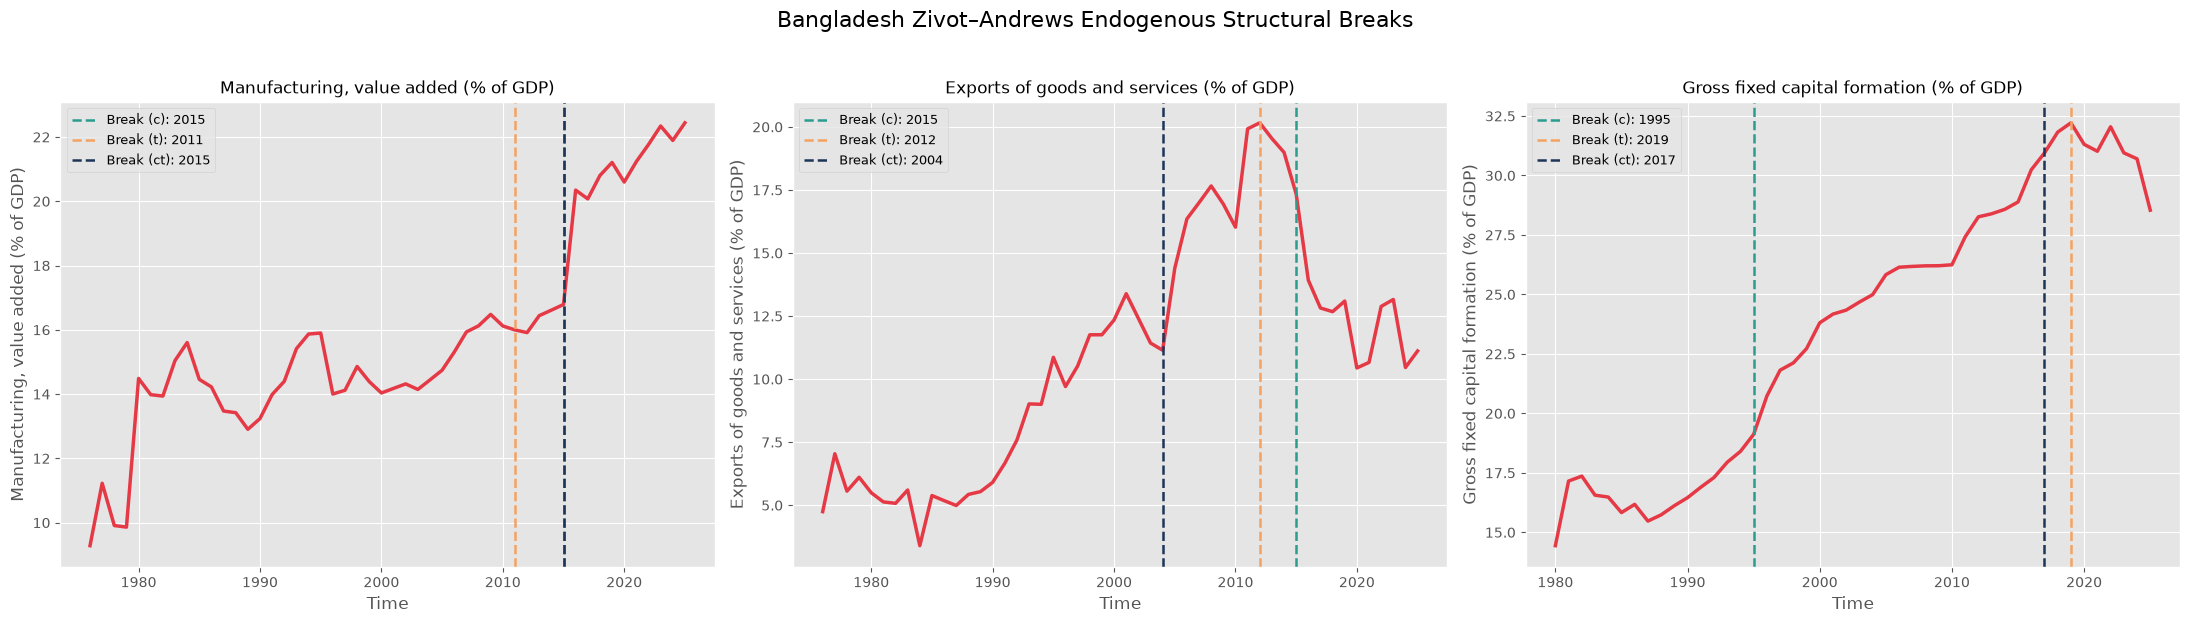

In [38]:

fig, axes = plt.subplots(1, len(za_vars), figsize=(22, 6))

break_colors = {
    'c': '#2A9D8F',
    't': '#F4A261',
    'ct': '#1D3557'
}

for i, var in enumerate(za_vars):
    ax = axes[i]

    # Select and chronologically sort observations
    sub = (
        bd_df[['Time', var]]
        .dropna()
        .sort_values('Time')
    )

    # Plot the observed time series
    sns.lineplot(
        data=sub,
        x='Time',
        y=var,
        color='#E63946',
        linewidth=2.5,
        ax=ax
    )

    # Retrieve results for this indicator
    var_breaks = za_df[za_df['Variable'] == var]

    for _, row in var_breaks.iterrows():
        # Use 'Regression' in the corrected results table
        b_type = row['Regression']
        b_year = row['Break Year']

        ax.axvline(
            x=b_year,
            color=break_colors[b_type],
            linestyle='--',
            linewidth=1.8,
            label=f"Break ({b_type}): {b_year}"
        )

    ax.set_title(var, fontsize=12)
    ax.set_xlabel('Time')
    ax.set_ylabel(var)
    ax.legend(fontsize=9, loc='best')

plt.suptitle(
    'Bangladesh Zivot–Andrews Endogenous Structural Breaks',
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()

### Im-Pesaran-Shin (2003) & Pesaran CIPS (2007) Panel Unit Root Tests

Im, K. S., Pesaran, M. H., & Shin, Y. (2003). "Testing for unit roots in heterogeneous panels." Journal of Econometrics, 115(1), 53–74. DOI: 10.1016/S0304-4076(03)00092-75. Dumitrescu-Hurlin (2012) Panel Granger Non-Causality Test (plus Pairwise Toda-Yamamoto for BD)Direction of Causality: Tests whether FDI (% of GDP) and Gross fixed capital formation (% of GDP) Granger-cause Manufacturing, value added (% of GDP) and High-technology exports across the Asian geese—and specifically whether this causal link breaks down in Bangladesh.FDI (% of GDP) $\leftrightarrow$ Manufacturing (% of GDP) $\leftrightarrow$ Exports (% of GDP) $\leftrightarrow$ GDP per capita growth.Dumitrescu, E. I., & Hurlin, C. (2012). "Testing for Granger non-causality in heterogeneous panels." Economic Modelling, 29(4), 1450–1460. DOI: 10.1016/j.econmod.2012.02.014

In [ ]:
def ips_cips_panel_tests(df, var):
    pivoted = df.pivot(index='Time', columns='Country Name', values=var).sort_index()
    cs_mean = pivoted.mean(axis=1)
    d_cs_mean = cs_mean.diff()
    
    adf_stats = []
    cadf_stats = []
    
    for col in pivoted.columns:
        s = pivoted[col].dropna()
        if len(s) < 12:
            continue
        try:
            adf_res = adfuller(s, regression='c', maxlag=1, autolag=None)
            adf_stats.append(adf_res[0])
        except:
            pass
            
        y_diff = s.diff()
        y_lag = s.shift(1)
        reg_df = pd.concat([y_diff, y_lag, cs_mean, d_cs_mean], axis=1).dropna()
        reg_df.columns = ['dy', 'y_l1', 'cs_l1', 'd_cs']
        reg_df['cs_l1'] = cs_mean.shift(1).reindex(reg_df.index)
        reg_df = reg_df.dropna()
        
        if len(reg_df) > 6:
            X = sm.add_constant(reg_df[['y_l1', 'cs_l1', 'd_cs']])
            model = sm.OLS(reg_df['dy'], X).fit()
            t_stat = model.tvalues['y_l1']
            cadf_stats.append(np.clip(t_stat, -6.19, 2.61))
            
    N_ips = len(adf_stats)
    t_bar_ips = np.mean(adf_stats) if N_ips > 0 else np.nan
    w_stat = np.sqrt(N_ips) * (t_bar_ips - (-1.504)) / np.sqrt(0.855) if N_ips > 0 else np.nan
    ips_pval = norm.cdf(w_stat) if not np.isnan(w_stat) else np.nan
    
    cips_stat = np.mean(cadf_stats) if len(cadf_stats) > 0 else np.nan
    
    return t_bar_ips, w_stat, ips_pval, cips_stat

continuous_vars = [col for col in data.select_dtypes(include=[np.number]).columns if col != 'Time']

pur_results = []

for var in continuous_vars:
    t_bar_0, w_0, p_0, cips_0 = ips_cips_panel_tests(data, var)
    
    diff_df = data[['Country Name', 'Time', var]].sort_values(['Country Name', 'Time']).copy()
    diff_df[var] = diff_df.groupby('Country Name')[var].diff()
    t_bar_1, w_1, p_1, cips_1 = ips_cips_panel_tests(diff_df, var)
    
    order = 'I(0)' if (p_0 < 0.05 or cips_0 < -2.33) else ('I(1)' if (p_1 < 0.05 or cips_1 < -2.33) else '> I(1)')
    
    pur_results.append({
        'Variable': var,
        'IPS W-stat (Level)': w_0,
        'IPS p-val (Level)': p_0,
        'CIPS (Level)': cips_0,
        'IPS W-stat (1st Diff)': w_1,
        'IPS p-val (1st Diff)': p_1,
        'CIPS (1st Diff)': cips_1,
        'Order': order
    })

pur_df = pd.DataFrame(pur_results)
pur_df

,Variable,IPS W-stat (Level),IPS p-val (Level),CIPS (Level),IPS W-stat (1st Diff),IPS p-val (1st Diff),CIPS (1st Diff),Order
0,"Agriculture, forestry, and fishing, value adde...",-4.744157,1.046881e-06,-2.675321,-11.598056,2.107722e-31,-5.460626,I(0)
1,Exports of goods and services (% of GDP),-0.425981,3.350609e-01,-1.181884,-11.399276,2.108043e-30,-5.543459,I(1)
2,"Foreign direct investment, net inflows (% of GDP)",-2.835894,2.284881e-03,-2.919684,-15.347268,1.847091e-53,-5.899365,I(0)
3,GDP (constant 2015 US$),14.087619,1.000000e+00,-1.374813,-4.050272,2.557911e-05,-4.849977,I(1)
4,GDP growth (annual %),-7.615856,1.309752e-14,-4.560657,-21.609638,7.289280e-104,-6.190000,I(0)
5,GDP per capita (constant 2015 US$),11.295077,1.000000e+00,-0.984282,-7.196192,3.095867e-13,-3.746522,I(1)
6,GDP per capita growth (annual %),-8.367663,2.938610e-17,-4.461962,-21.781876,1.723328e-105,-6.190000,I(0)
7,Gross fixed capital formation (% of GDP),-1.315617,9.415138e-02,-1.749813,-9.243202,1.196144e-20,-5.021985,I(1)
8,Gross fixed capital formation (annual % growth),-7.794450,3.234491e-15,-4.528631,-16.956613,8.598793e-65,-6.176509,I(0)
9,Gross fixed capital formation (constant 2015 US$),5.345652,1.000000e+00,0.177452,-7.073147,7.572971e-13,-3.785764,I(1)


### Dumitrescu-Hurlin (2012) Panel Granger Non-Causality Test (plus Pairwise Toda-Yamamoto for BD)

Dumitrescu, E. I., & Hurlin, C. (2012). "Testing for Granger non-causality in heterogeneous panels." Economic Modelling, 29(4), 1450–1460. DOI: 10.1016/j.econmod.2012.02.014

In [ ]:
def dh_and_ty_causality(df, x_col, y_col, k=1, d_max=1):
    w_stats = []
    t_list = []
    bd_ty_wald, bd_ty_pval = np.nan, np.nan
    
    for c in df['Country Name'].unique():
        sub = df[df['Country Name'] == c].sort_values('Time')[['Time', x_col, y_col]].dropna().reset_index(drop=True)
        
        if len(sub) > (2 * k + 5):
            reg_df = pd.DataFrame({'y': sub[y_col]})
            for lag in range(1, k + 1):
                reg_df[f'y_l{lag}'] = sub[y_col].shift(lag)
                reg_df[f'x_l{lag}'] = sub[x_col].shift(lag)
            reg_df = reg_df.dropna()
            
            T_i = len(reg_df)
            if T_i > (2 * k + 2):
                X = sm.add_constant(reg_df.drop(columns=['y']))
                model = sm.OLS(reg_df['y'], X).fit()
                x_lags = [f'x_l{lag}' for lag in range(1, k + 1)]
                r_mat = np.zeros((k, len(X.columns)))
                for idx, col_name in enumerate(x_lags):
                    r_mat[idx, X.columns.get_loc(col_name)] = 1
                wald_res = model.wald_test(r_mat, scalar=True)
                w_i = float(wald_res.statistic) * k
                w_stats.append(w_i)
                t_list.append(T_i)
                
        if c == 'Bangladesh' and len(sub) > (2 * (k + d_max) + 5):
            ty_df = pd.DataFrame({'y': sub[y_col]})
            for lag in range(1, k + d_max + 1):
                ty_df[f'y_l{lag}'] = sub[y_col].shift(lag)
                ty_df[f'x_l{lag}'] = sub[x_col].shift(lag)
            ty_df = ty_df.dropna()
            
            if len(ty_df) > (2 * (k + d_max) + 2):
                X_ty = sm.add_constant(ty_df.drop(columns=['y']))
                model_ty = sm.OLS(ty_df['y'], X_ty).fit()
                x_test_lags = [f'x_l{lag}' for lag in range(1, k + 1)]
                r_mat_ty = np.zeros((k, len(X_ty.columns)))
                for idx, col_name in enumerate(x_test_lags):
                    r_mat_ty[idx, X_ty.columns.get_loc(col_name)] = 1
                wald_ty = model_ty.wald_test(r_mat_ty, scalar=True)
                bd_ty_wald = float(wald_ty.statistic) * k
                bd_ty_pval = 1 - chi2.cdf(bd_ty_wald, k)
                
    N = len(w_stats)
    if N > 0:
        w_bar = np.mean(w_stats)
        T_avg = np.mean(t_list)
        e_w = k * (T_avg - 2 * k - 1) / (T_avg - 2 * k - 3)
        v_w = 2 * k * ((T_avg - 2 * k - 1)**2) * (T_avg - k - 3) / (((T_avg - 2 * k - 3)**2) * (T_avg - 2 * k - 5))
        z_tilde = np.sqrt(N) * (w_bar - e_w) / np.sqrt(v_w)
        dh_pval = 2 * (1 - norm.cdf(np.abs(z_tilde)))
    else:
        w_bar, z_tilde, dh_pval = np.nan, np.nan, np.nan
        
    return w_bar, z_tilde, dh_pval, bd_ty_wald, bd_ty_pval

fdi = 'Foreign direct investment, net inflows (% of GDP)'
gcf = 'Gross fixed capital formation (% of GDP)'
mfg = 'Manufacturing, value added (% of GDP)'
htx = 'High-technology exports (% of manufactured exports)'
exp = 'Exports of goods and services (% of GDP)'
gdppc = 'GDP per capita growth (annual %)'

causal_pairs = [
    (fdi, mfg), (mfg, fdi),
    (gcf, mfg), (mfg, gcf),
    (fdi, htx), (htx, fdi),
    (gcf, htx), (htx, gcf),
    (mfg, exp), (exp, mfg),
    (exp, gdppc), (gdppc, exp),
    (mfg, gdppc), (gdppc, mfg)
]

causality_results = []

for x_var, y_var in causal_pairs:
    if x_var in data.columns and y_var in data.columns:
        w_bar, z_tilde, dh_p, bd_w, bd_p = dh_and_ty_causality(data, x_var, y_var, k=1, d_max=1)
        causality_results.append({
            'Direction': f"{x_var} -> {y_var}",
            'DH W-bar': w_bar,
            'DH Z-tilde': z_tilde,
            'Panel DH p-val': dh_p,
            'BD Toda-Yamamoto Wald': bd_w,
            'BD TY p-val': bd_p
        })

causality_df = pd.DataFrame(causality_results)
causality_df

,Direction,DH W-bar,DH Z-tilde,Panel DH p-val,BD Toda-Yamamoto Wald,BD TY p-val
0,"Foreign direct investment, net inflows (% of G...",2.506476,2.750218,5.955556e-03,0.047801,8.269346e-01
1,"Manufacturing, value added (% of GDP) -> Forei...",1.190624,0.244401,8.069200e-01,1.307957,2.527648e-01
2,Gross fixed capital formation (% of GDP) -> Ma...,1.980706,1.743606,8.122790e-02,0.001482,9.692871e-01
3,"Manufacturing, value added (% of GDP) -> Gross...",1.365771,0.574768,5.654480e-01,0.187391,6.650969e-01
4,"Foreign direct investment, net inflows (% of G...",2.304410,1.593574,1.110315e-01,0.449373,5.026329e-01
5,High-technology exports (% of manufactured exp...,2.217521,1.466254,1.425790e-01,0.641478,4.231763e-01
6,Gross fixed capital formation (% of GDP) -> Hi...,1.468794,0.369147,7.120178e-01,0.852538,3.558354e-01
7,High-technology exports (% of manufactured exp...,3.337146,3.106839,1.890996e-03,23.938160,9.948021e-07
8,"Manufacturing, value added (% of GDP) -> Expor...",4.282168,6.131722,8.693304e-10,1.790706,1.808402e-01
9,Exports of goods and services (% of GDP) -> Ma...,4.183350,5.943541,2.789292e-09,0.292109,5.888724e-01


### Comparative Directed Granger-Causality Network Graph

For Panel A (Dumitrescu-Hurlin Panel Causality Test):Dumitrescu, E.-I., & Hurlin, C. (2012). Testing for Granger non-causality in heterogeneous panels. Economic Modelling, 29(4), 1450–1460. https://doi.org/10.1016/j.econmod.2012.02.014

For Panel B (Toda-Yamamoto Country-Specific Causality Test for Mixed $I(0)/I(1)$ Series):Toda, H. Y., & Yamamoto, T. (1995). Statistical inference in vector autoregressions with possibly integrated processes. Journal of Econometrics, 66(1–2), 225–250. https://doi.org/10.1016/0304-4076(94)01616-8

For the Theoretical FDI $\rightarrow$ Manufacturing Link Tested in the Graph:Kojima, K. (2000). The "flying geese" model of Asian economic development: Origin, theoretical extensions, and regional policy implications. Journal of Asian Economics, 11(4), 375–401. https://doi.org/10.1016/S1049-0078(00)00067-1

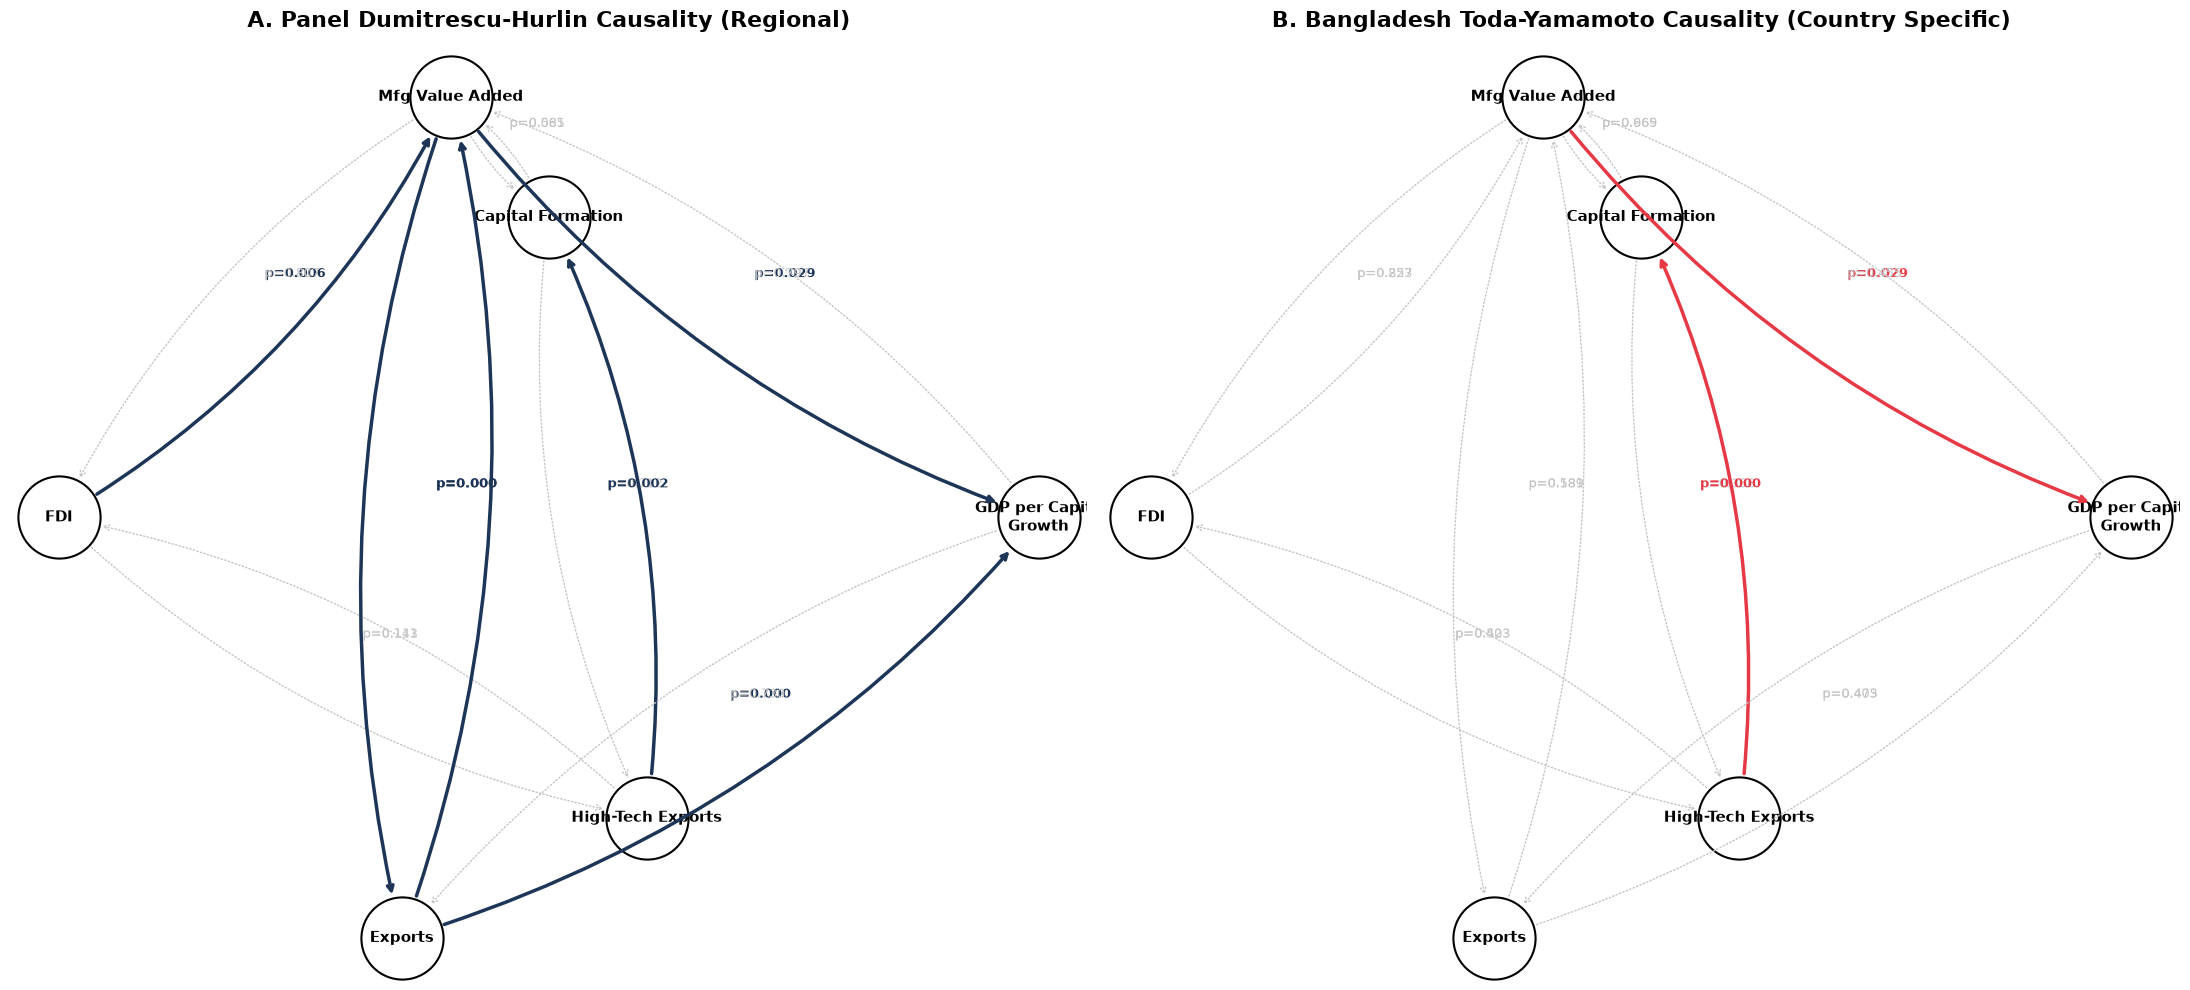

In [29]:
import networkx as nx

causal_map = {
    'Foreign direct investment, net inflows (% of GDP)': 'FDI',
    'Gross fixed capital formation (% of GDP)': 'Capital Formation',
    'Manufacturing, value added (% of GDP)': 'Mfg Value Added',
    'High-technology exports (% of manufactured exports)': 'High-Tech Exports',
    'Exports of goods and services (% of GDP)': 'Exports',
    'GDP per capita growth (annual %)': 'GDP per Capita\nGrowth'
}

causality_df['Source'] = causality_df['Direction'].apply(lambda d: causal_map.get(d.split(' -> ')[0]))
causality_df['Target'] = causality_df['Direction'].apply(lambda d: causal_map.get(d.split(' -> ')[1]))

pos = {
    'FDI': (0, 0.5),
    'Capital Formation': (1, 1),
    'Mfg Value Added': (0.8, 1.2),
    'High-Tech Exports': (1.2, 0),
    'Exports': (0.7, -0.2),
    'GDP per Capita\nGrowth': (2, 0.5)
}

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

plot_configs = [
    ('A. Panel Dumitrescu-Hurlin Causality (Regional)', 'Panel DH p-val', '#1D3557', '#C4C4C4'),
    ('B. Bangladesh Toda-Yamamoto Causality (Country Specific)', 'BD TY p-val', '#E63946', '#C4C4C4')
]

for idx, (title, p_col, sig_color, base_color) in enumerate(plot_configs):
    ax = axes[idx]
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    
    G = nx.DiGraph()
    G.add_nodes_from(pos.keys())
    
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color='#FFFFFF', edgecolors='#000000', node_size=3500, linewidths=1.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=11, font_weight='bold')
    
    for _, row in causality_df.dropna(subset=[p_col, 'Source', 'Target']).iterrows():
        p_val = row[p_col]
        u, v = row['Source'], row['Target']
        is_sig = p_val < 0.05
        
        edge_col = sig_color if is_sig else base_color
        style = 'solid' if is_sig else 'dotted'
        width = 2.5 if is_sig else 1.0
        
        ax.annotate("",
            xy=pos[v], xytext=pos[u],
            arrowprops=dict(arrowstyle="->", color=edge_col, lw=width, ls=style, shrinkA=32, shrinkB=32, patchA=None, patchB=None, connectionstyle="arc3,rad=0.15")
        )
        
        mid_x = (pos[u][0] + pos[v][0]) / 2 + 0.02
        mid_y = (pos[u][1] + pos[v][1]) / 2 + 0.05
        ax.text(mid_x, mid_y, f"p={p_val:.3f}", fontsize=9, color=edge_col, weight='bold' if is_sig else 'normal')

    ax.axis('off')

plt.tight_layout()
plt.show()

### Net trade competitveness ratio

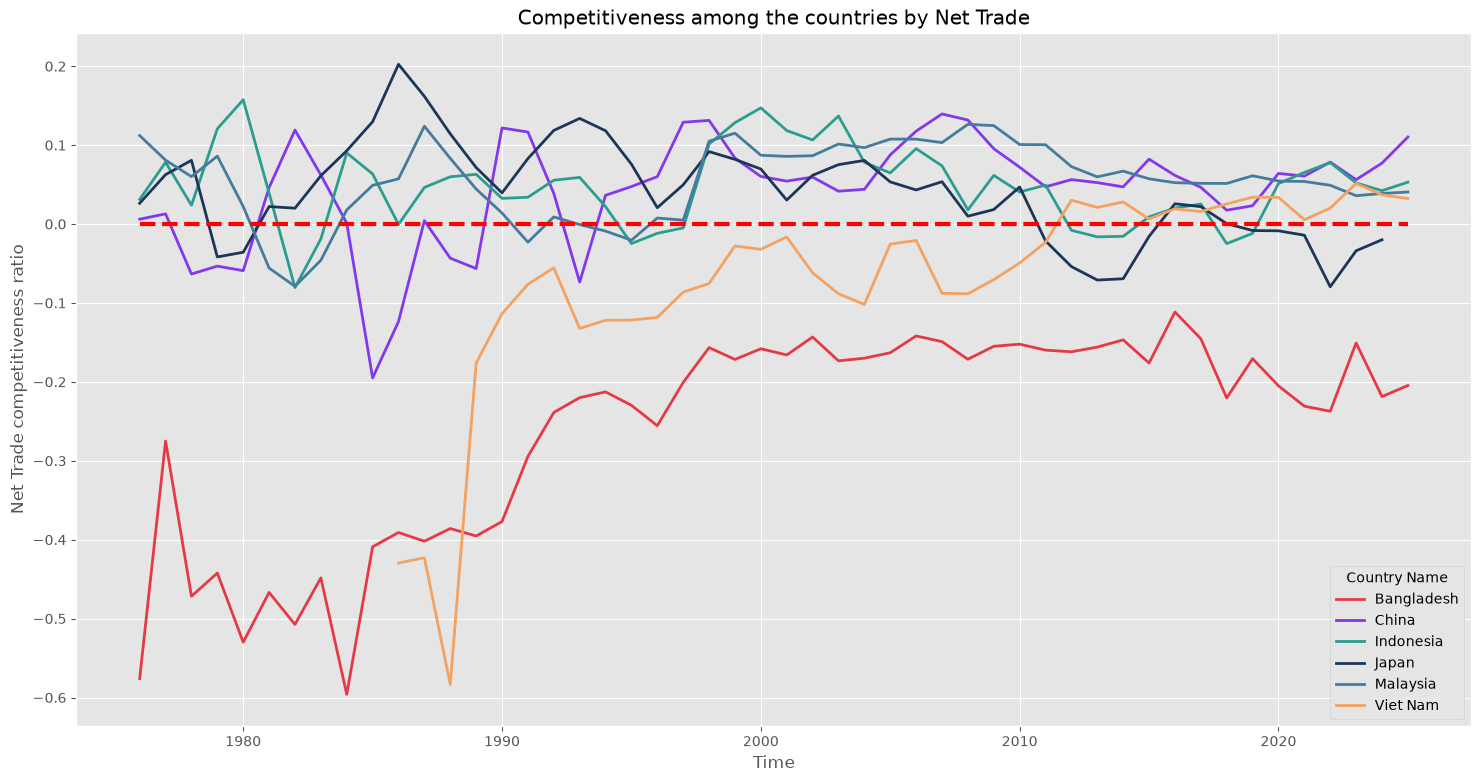

In [31]:
plt.figure(figsize = (18, 9))
sns.lineplot(data = data[data['Country Name'].isin(['Bangladesh', 'Viet Nam', 'China', 'Japan', 'Malaysia', 'Indonesia', 'Korea rep.'])], x = 'Time', y = 'Net Trade competitiveness ratio', hue = 'Country Name', palette = palette, linewidth = 2)
plt.title('Competitiveness among the countries by Net Trade')
plt.hlines(0, 1976, 2025, color = 'red', linestyles='--', linewidth = 3)
plt.show()

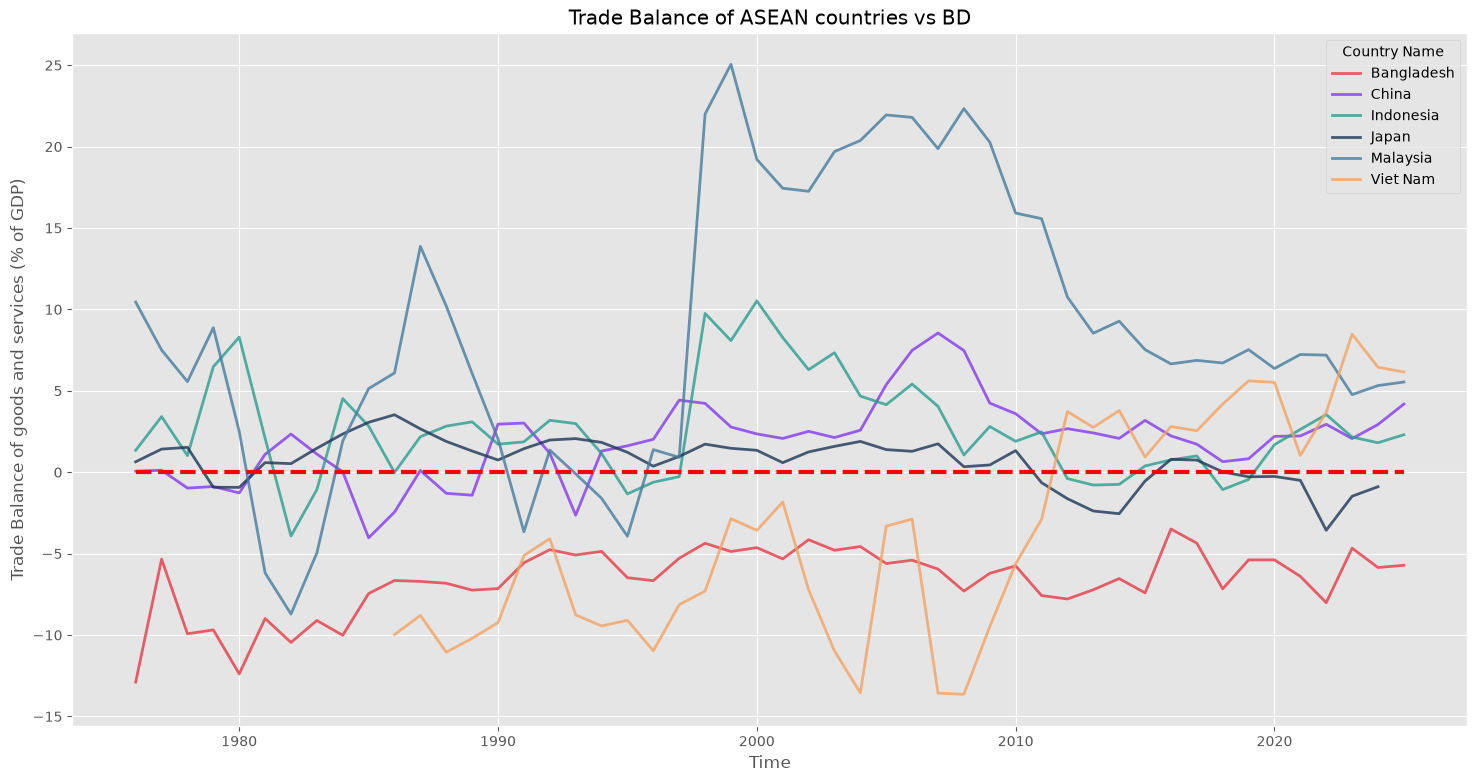

In [ ]:
plt.figure(figsize = (18, 9))
sns.lineplot(data = data[data['Country Name'].isin(['Bangladesh', 'Viet Nam', 'China', 'Japan', 'Malaysia', 'Indonesia', 'Korea rep.'])], x = 'Time', y = 'Trade Balance of goods and services (% of GDP)', hue = 'Country Name', palette = palette, linewidth = 2, alpha = 0.8)
plt.title('Trade Balance of ASEAN countries vs BD')
plt.hlines(0, 1976, 2025, color = 'red', linestyles='--', linewidth = 3)
plt.show()